In [3]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from sklearn.decomposition import NMF
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="dark", context="notebook")

TARGET_STROKE = "flam_mid" 
data_dir = os.path.join("..", "data", "raw", TARGET_STROKE)
wav_files = glob.glob(os.path.join(data_dir, "*.wav"))

if not wav_files:
    print(f"No .wav files found for '{TARGET_STROKE}' in {data_dir}.")

# Load a single representative high-quality stroke for deep separation analysis
sample_path = wav_files[0]
y, sr = librosa.load(sample_path, sr=44100)
# Trim trailing silence for a cleaner analysis window
y, _ = librosa.effects.trim(y, top_db=30)

print(f"Analyzing {os.path.basename(sample_path)} (Length: {len(y)/sr*1000:.1f} ms)")

Analyzing GIO_MEE_tombak_flam_mid.wav (Length: 243.8 ms)


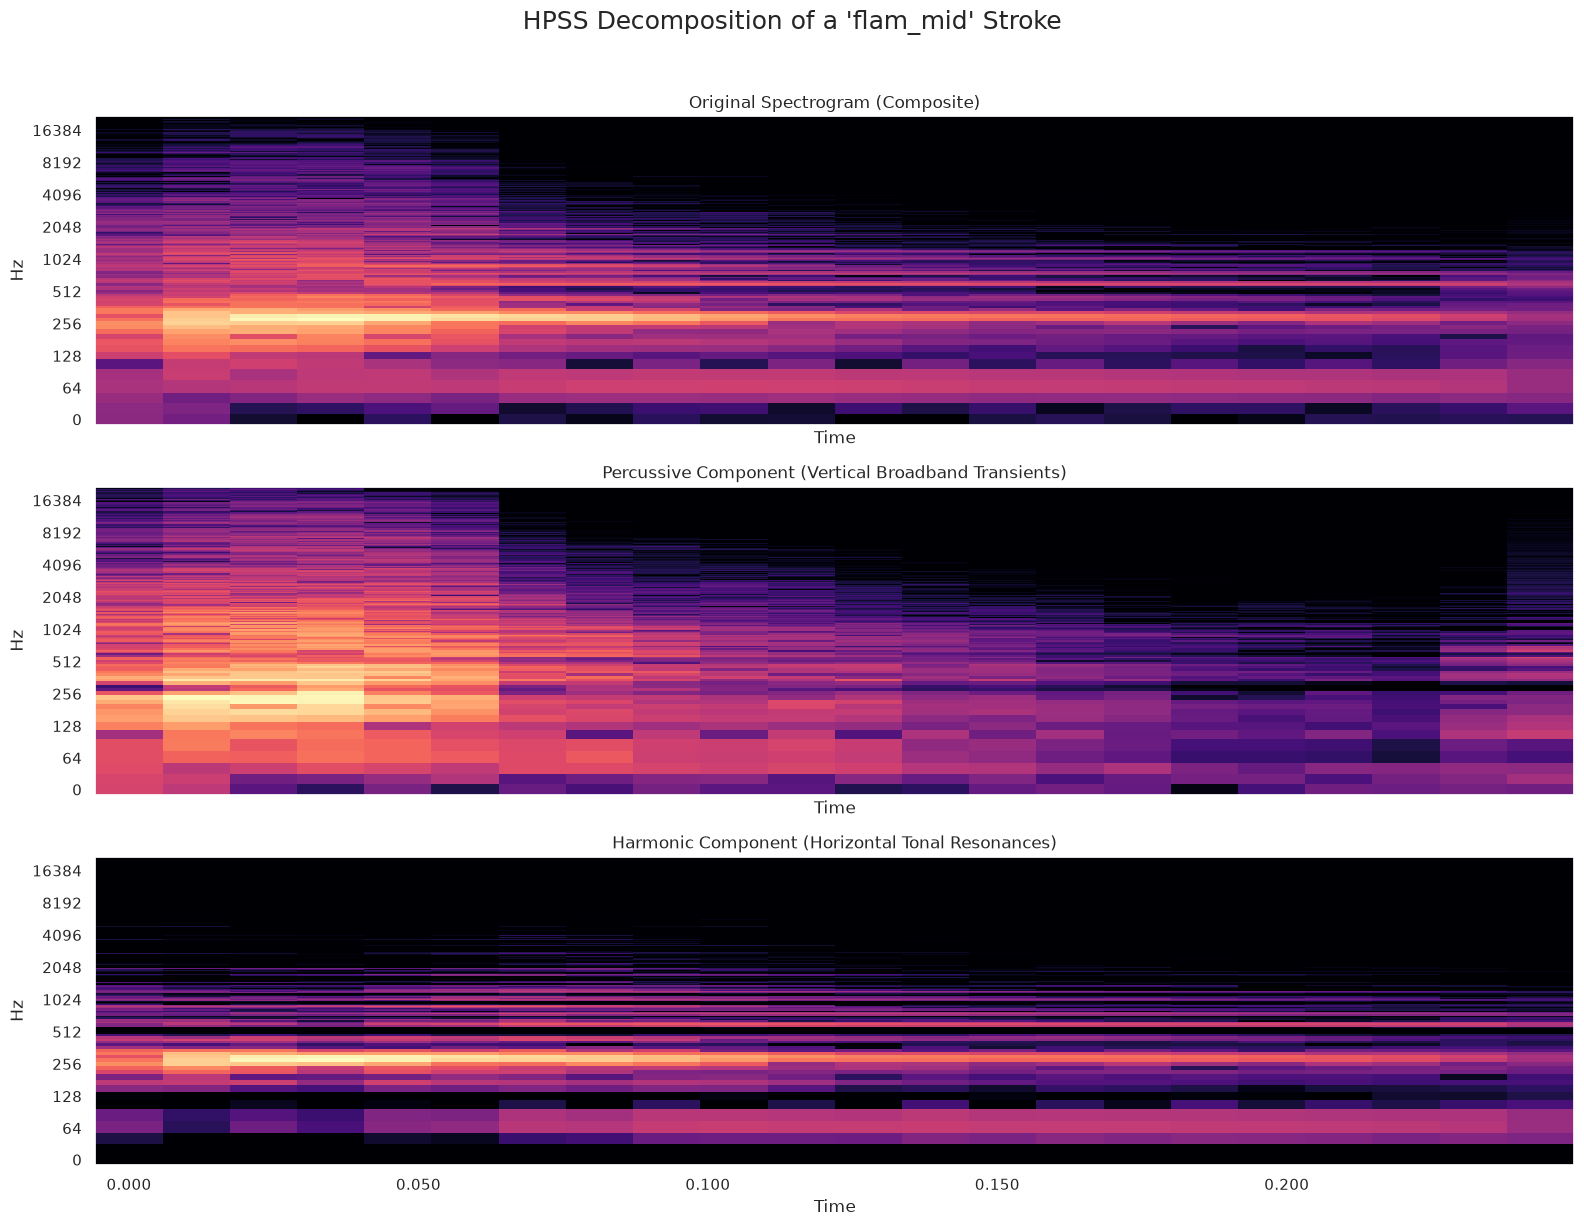

In [4]:
S = np.abs(librosa.stft(y))
H, P = librosa.decompose.hpss(S)

# Reconstruct the audio for the separated components
y_harmonic = librosa.istft(H)
y_percussive = librosa.istft(P)

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)
fig.suptitle(f"HPSS Decomposition of a '{TARGET_STROKE}' Stroke", fontsize=18, y=1.02)

# Plot Original
librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max), y_axis='log', x_axis='time', sr=sr, ax=axes[0], cmap='magma')
axes[0].set_title("Original Spectrogram (Composite)")

# Plot Percussive (The Skin/Wood Hit)
librosa.display.specshow(librosa.amplitude_to_db(P, ref=np.max), y_axis='log', x_axis='time', sr=sr, ax=axes[1], cmap='magma')
axes[1].set_title("Percussive Component (Vertical Broadband Transients)")

# Plot Harmonic (The Cavity Resonance)
librosa.display.specshow(librosa.amplitude_to_db(H, ref=np.max), y_axis='log', x_axis='time', sr=sr, ax=axes[2], cmap='magma')
axes[2].set_title("Harmonic Component (Horizontal Tonal Resonances)")

plt.tight_layout()
plt.show()

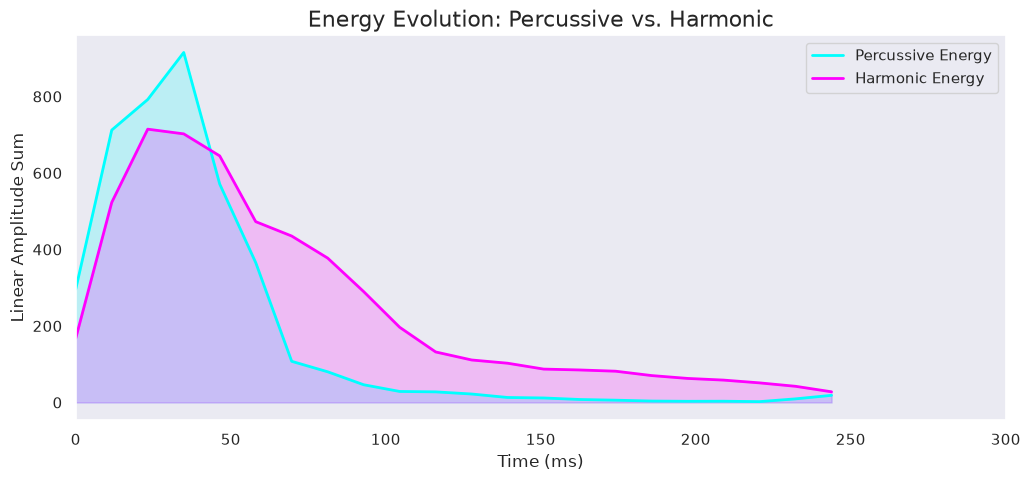

In [5]:
p_energy = np.sum(P, axis=0)
h_energy = np.sum(H, axis=0)
time_axis = librosa.frames_to_time(range(S.shape[1]), sr=sr) * 1000

plt.figure(figsize=(12, 5))
plt.plot(time_axis, p_energy, label='Percussive Energy', color='cyan', linewidth=2)
plt.plot(time_axis, h_energy, label='Harmonic Energy', color='magenta', linewidth=2)
plt.fill_between(time_axis, p_energy, alpha=0.2, color='cyan')
plt.fill_between(time_axis, h_energy, alpha=0.2, color='magenta')

plt.title("Energy Evolution: Percussive vs. Harmonic", fontsize=16)
plt.xlabel("Time (ms)")
plt.ylabel("Linear Amplitude Sum")
plt.legend()
plt.xlim(0, 300)
plt.show()

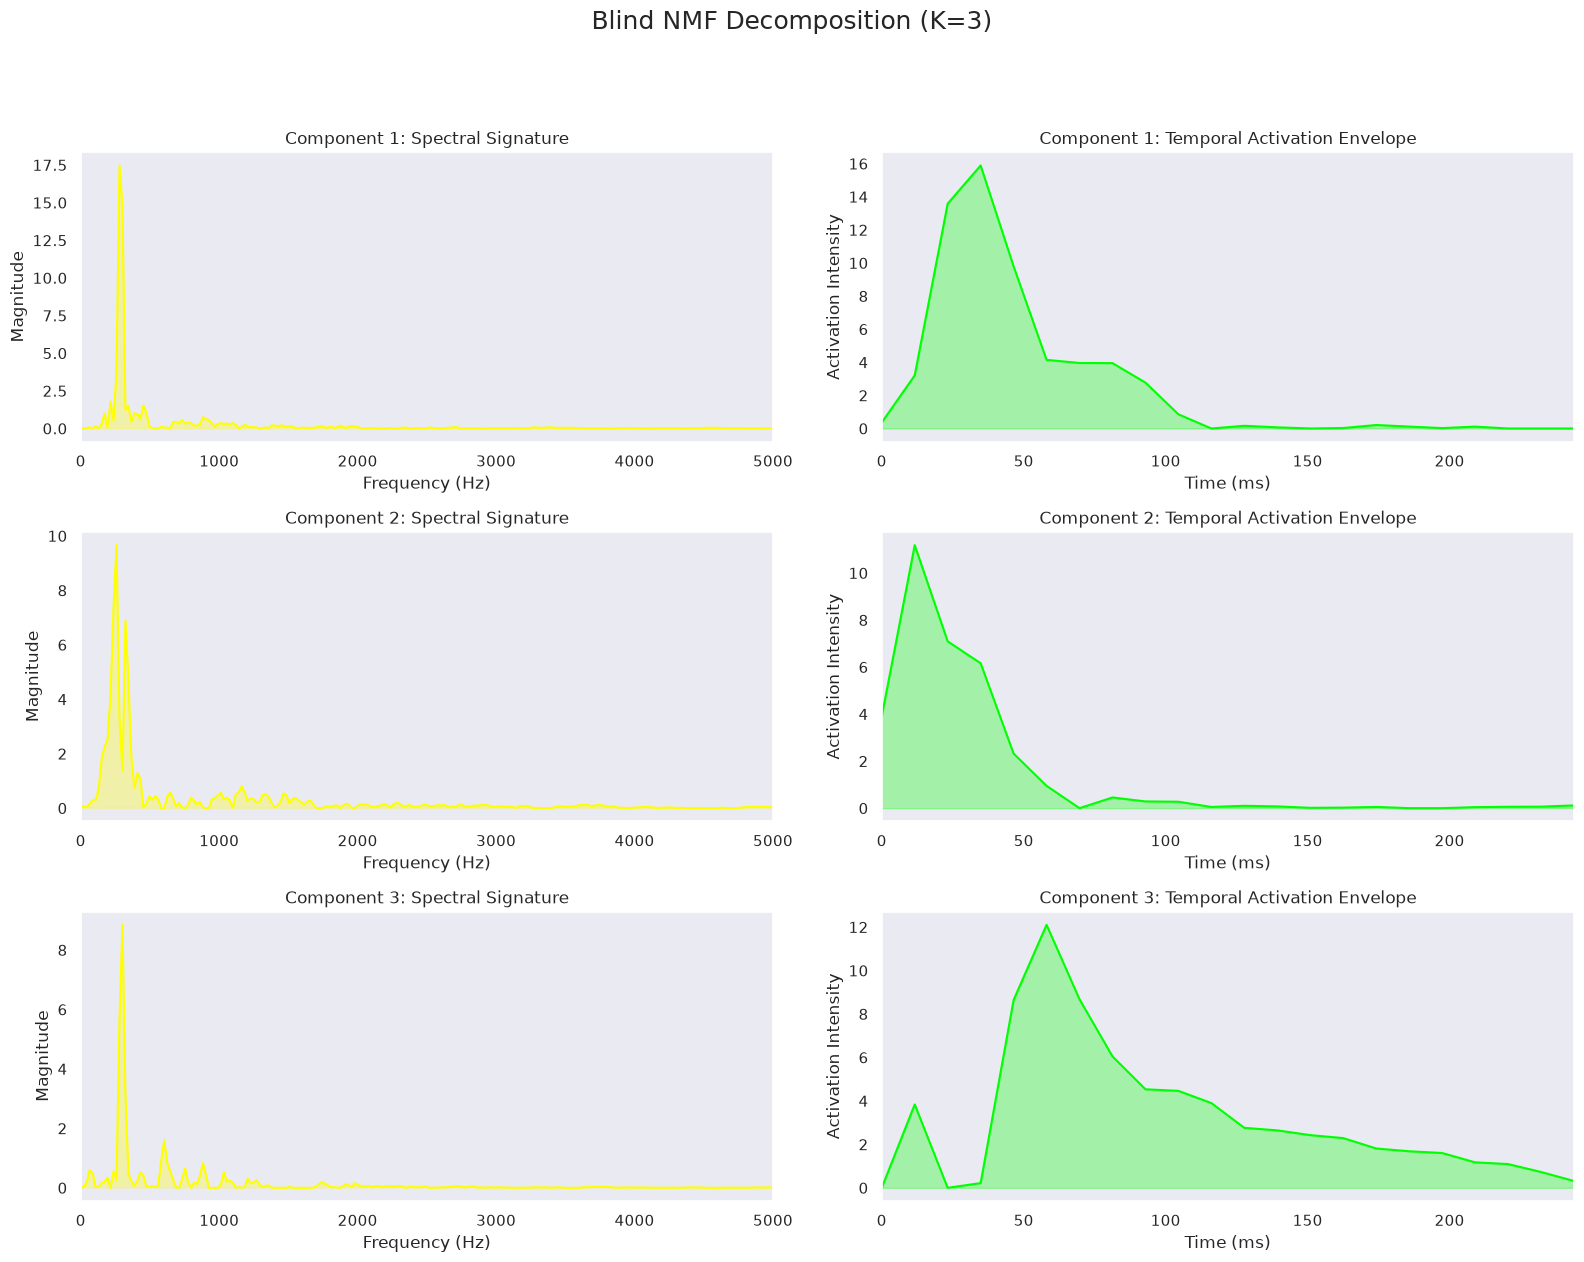

In [8]:
K_COMPONENTS = 3

# Fit NMF on the magnitude spectrogram
nmf = NMF(n_components=K_COMPONENTS, init='nndsvda', random_state=42, max_iter=500)
W = nmf.fit_transform(S)  # W: Spectral Templates (What frequencies make up this component?)
H_act = nmf.components_     # H_act: Temporal Activations (When does this component happen?)

fig, axes = plt.subplots(K_COMPONENTS, 2, figsize=(16, 4 * K_COMPONENTS))
fig.suptitle(f"Blind NMF Decomposition (K={K_COMPONENTS})", fontsize=18, y=1.05)

freqs = librosa.fft_frequencies(sr=sr)
times = librosa.frames_to_time(range(H_act.shape[1]), sr=sr) * 1000

for k in range(K_COMPONENTS):
    # Plot Spectral Template (The Frequency "Signature")
    axes[k, 0].plot(freqs, W[:, k], color='yellow')
    axes[k, 0].fill_between(freqs, W[:, k], color='yellow', alpha=0.3)
    axes[k, 0].set_title(f"Component {k+1}: Spectral Signature")
    axes[k, 0].set_xlabel("Frequency (Hz)")
    axes[k, 0].set_ylabel("Magnitude")
    axes[k, 0].set_xlim(0, 5000) # Zoom in on the main action
    
    # Plot Temporal Activation (The Envelope)
    axes[k, 1].plot(times, H_act[k, :], color='lime')
    axes[k, 1].fill_between(times, H_act[k, :], color='lime', alpha=0.3)
    axes[k, 1].set_title(f"Component {k+1}: Temporal Activation Envelope")
    axes[k, 1].set_xlabel("Time (ms)")
    axes[k, 1].set_ylabel("Activation Intensity")
    axes[k, 1].set_xlim(0, max(times))

plt.tight_layout()
plt.show()

In [9]:
import IPython.display as ipd

phase = np.exp(1j * np.angle(librosa.stft(y)))

print("Original Stroke:")
display(ipd.Audio(y, rate=sr))

for k in range(K_COMPONENTS):
    # Reconstruct the STFT for just this component: W_k * H_k
    S_k = np.outer(W[:, k], H_act[k, :])
    
    # Invert back to audio using the original phase
    y_k = librosa.istft(S_k * phase)
    
    print(f"\nNMF Component {k+1}:")
    display(ipd.Audio(y_k, rate=sr))

Original Stroke:



NMF Component 1:



NMF Component 2:



NMF Component 3:
